Slope: 1.7112994698840884
Intercept: 14964.259052908981

Linear Regression Equation:
Price = 1.7112994698840884 * Levy + 14964.259052908981


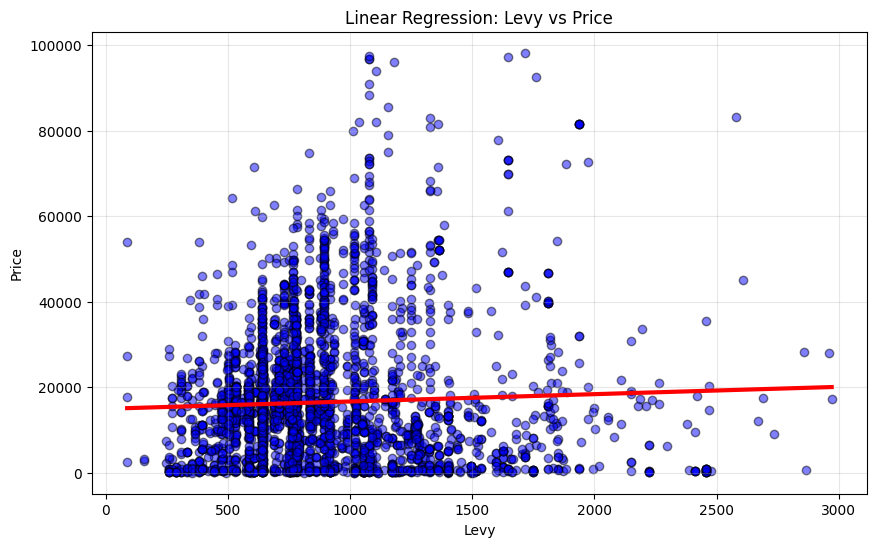

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# Read CSV file
df = pd.read_csv("/content/cartest.csv")
# Select required columns
data = df[['Levy', 'Price']].copy()
# Convert to numeric
data['Levy'] = pd.to_numeric(data['Levy'], errors='coerce')
data['Price'] = pd.to_numeric(data['Price'], errors='coerce')
# Remove missing values
data = data.dropna()
# Remove extreme outliers
data = data[
(data['Levy'] <= 3000) &
(data['Price'] <= 100000)
]
X = data[['Levy']]
y = data['Price']
model = LinearRegression()
model.fit(X, y)
# Predict values
y_pred = model.predict(X)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("\nLinear Regression Equation:")
print("Price =", model.coef_[0], "* Levy +", model.intercept_)
# Sort values for a smooth regression line
sort_index = X['Levy'].argsort()
X_sorted = X.iloc[sort_index]
y_pred_sorted = y_pred[sort_index]
plt.figure(figsize=(10, 6))
# Data points
plt.scatter(
X,
y,
alpha=0.5,
color='blue',
edgecolors='black'
)
# Regression line
plt.plot(
X_sorted,
y_pred_sorted,
color='red',
linewidth=3
)
# Labels and title
plt.xlabel("Levy")
plt.ylabel("Price")
plt.title("Linear Regression: Levy vs Price")
plt.grid(True, alpha=0.3)
plt.show()